# 01 · Quick start

Build a turbulent space-to-ground channel, run it for 200 ticks and look at what comes out.

The quick-start channel is a 256 × 256 grid (1 cm pixels, so 2.56 m across) with 10 turbulent layers between the
ground and a satellite at zenith, a total Fried parameter r₀ = 10 cm at 1550 nm, and 1 ms per tick. Every tick
the layers move with their wind and the downlink field is propagated through all of them to the ground. The
output is one complex field per tick: its magnitude squared is the irradiance a receiver sees and its angle is
the wavefront phase.

Command-line equivalent of this notebook: `opal run -c configs/quickstart_256.json -o runs/quickstart`, then
`opal view runs/quickstart` (README §2).

> **About the outputs.** The results stored in this notebook were produced on an NVIDIA GeForce RTX 4080
> (16 GiB) under Windows. Timings, and the run mode the memory guard picks, depend on the GPU; the statistics
> do not. Open the notebook in Jupyter or VS Code with the OPAL environment as the kernel and run the cells in
> order. The first cell moves to the repository root, so every path below is relative to it.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow's C++ start-up messages
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
os.chdir(ROOT)                                           # paths below are relative to the repository root

import time
import numpy as np
import matplotlib.pyplot as plt
import opal

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower"})
print("OPAL", opal.__version__)

OPAL 1.1.0


## 1. Load a configuration

A config has a `simulation_params` section (ticks, tick length, seed) and a `channel_params` section (grid,
layers, r₀, wavelength, wind, satellite geometry). `load_config` fills in defaults and validates everything; each
entry carries its value and a description. README §3 lists every parameter with its unit.

In [2]:
config = opal.load_config("configs/quickstart_256.json")
for section in ("simulation_params", "channel_params"):
    print(section)
    for key, entry in config[section].items():
        print(f"  {key:26s} {entry['value']!s:>10}   {entry['description']}")

simulation_params
  num_steps                         200   Number of simulation ticks.
  time_per_tick                   0.001   Duration of one tick (s).
  seed                                1   Master seed; per-layer seeds are derived from it. null = random.
channel_params
  phase_screen_size                 256   Grid size N (pixels, even).
  pixel_size                       0.01   Grid spacing (m).
  num_layers                         10   Number of phase-screen layers.
  total_r0                          0.1   Total path Fried parameter r0 (m).
  wavefront_wavelength         1.55e-06   Optical wavelength (m).
  L0                               25.0   Von Karman outer scale (m).
  ground_wind_speed                 5.0   Ground wind speed in the Bufton model (m/s).
  satellite_orbit_altitude     600000.0   Circular-orbit altitude of the satellite (m); sets the slew-induced wind.
  satellite_zenith_angle            0.0   Zenith angle of the line of sight (deg, 0 = overhead) at whic

## 2. Build the simulator

Building draws the initial phase screen of every layer and precomputes the extrusion operators that move each
screen with its wind (README §13). This is done once; ticks then run inside a compiled TensorFlow graph.

`describe()` shows the per-layer profile: the height of each layer, its share of the turbulence (its own r₀),
its wind, and how many new screen rows it receives per tick (`rows_extruded`, a whole number).

In [3]:
t0 = time.time()
sim = opal.GpuSimulator(config)
print(f"built in {time.time() - t0:.1f} s")

info = sim.describe()
print(f"grid {info['grid']} x {info['grid']} at {info['pixel_size_m']} m per pixel, total r0 {info['total_r0_m']} m, "
      f"D/r0 = {info['D_over_r0']:.1f} over the whole grid, seed {info['seed']}\n")
print("layer   height (m)   r0 (m)   wind (m/s)   rows/tick   rows extruded")
for layer in info["layers"]:
    print(f"{layer['layer']:5d} {layer['height_m']:12.0f} {layer['r0_m']:8.3f} {layer['wind_mps']:12.1f} "
          f"{layer['rows_per_tick']:11.2f} {layer['rows_extruded']:15d}")

built in 6.0 s
grid 256 x 256 at 0.01 m per pixel, total r0 0.1 m, D/r0 = 25.6 over the whole grid, seed 1

layer   height (m)   r0 (m)   wind (m/s)   rows/tick   rows extruded
    0           95    0.141          6.9        0.69               2
    1          179    0.260          8.0        0.80               2
    2          330    0.349         10.0        1.00               3
    3         1416    0.547         24.7        2.47               5
    4         3785    1.086         60.3        6.03              13
    5         7942    1.725        132.4       13.24              27
    6        10063    2.157        161.2       16.12              33
    7        11888    2.375        177.7       17.77              36
    8        14096    2.578        194.1       19.41              39
    9        20065    2.870        258.0       25.80              52


## 3. Run it

`opal.run` picks a run mode with the memory guard (here everything fits on the GPU, so `device`), simulates,
and writes `frames.npy` (complex64 `[200, 256, 256]`) plus a `manifest.json` that records exactly how the run
was made (config, seed, versions, timings, memory). The log lines are the same ones the CLI prints.

In [4]:
result = opal.run(sim, out_dir="runs/quickstart")

print(f"\n{result.mode} mode: {result.num_steps} ticks in {result.run_time_s:.2f} s "
      f"({result.steps_per_second:.0f} ticks/s)")
print("frames:", result.frames.shape, result.frames.dtype)
print("files: ", sorted(p.name for p in Path("runs/quickstart").iterdir()))

[opal    2.38s] memory plan: N=256 steps=200 requested=auto -> device


[opal    2.38s]   frame 0.5 MiB | output 0.10 GiB | baseline 0.04 GiB | margin 3.20 GiB | GPU 15.99 GiB | RAM avail 36.48 GiB


[opal    2.38s]   predicted GPU peak: device 3.43 GiB | host 3.24 GiB | chunked 3.34 GiB (chunk<=100)


[opal    2.38s] guard: auto: full output fits on the GPU -> device


[opal    2.38s] running device mode: 200 steps, N=256, 10 layers


[opal   32.32s] device: 200 steps in 29.94 s (149.72 ms/step)


[opal   32.41s] wrote frames.npy (0.10 GiB) in 0.1 s


[opal   32.42s] done: 200 steps simulated in 29.94 s | 6.7 steps/s | peak GPU 0.24 GiB | writing frames 0.1 s


[opal   32.42s] wrote runs\quickstart\manifest.json



device mode: 200 ticks in 29.94 s (7 ticks/s)
frames: (200, 256, 256) complex64
files:  ['frames.npy', 'manifest.json']


## 4. Look at the last frame

Irradiance is shown relative to its mean (1 = the average power density). The bright speckles and dark holes
are scintillation, produced as the phase distortions of the higher layers turn into intensity fluctuations on
the way down. The dashed circle is a 1 m receiver aperture, well inside the absorbing boundary at the grid edge.

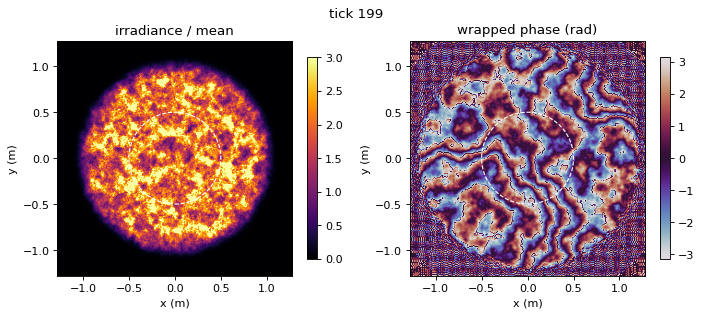

1 m aperture: mean irradiance 0.954, scintillation index 0.102
r0 measured from this single frame: 0.096 m (configured 0.1 m)


In [5]:
from opal.analysis import aperture_mask, estimate_r0_from_wavefront, scintillation_index

N, dx = info["grid"], info["pixel_size_m"]
last = np.asarray(result.frames[-1])
irr, phase = opal.viewer.field_images(last)
half = N * dx / 2

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
panels = [(irr, "inferno", 0, 3, "irradiance / mean"), (phase, "twilight", -np.pi, np.pi, "wrapped phase (rad)")]
for ax, (img, cmap, lo, hi, title) in zip(axes, panels):
    im = ax.imshow(img, cmap=cmap, vmin=lo, vmax=hi, extent=[-half, half, -half, half])
    ax.add_patch(plt.Circle((0, 0), 0.5, fill=False, color="w", ls="--", lw=1))
    ax.set(title=title, xlabel="x (m)", ylabel="y (m)")
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle(f"tick {result.num_steps - 1}")
plt.tight_layout()
plt.show()

pupil = aperture_mask(N, dx, 1.0)
r0 = estimate_r0_from_wavefront(last, dx, L0=25.0)["measured_r0"]
print(f"1 m aperture: mean irradiance {(np.abs(last) ** 2)[pupil].mean():.3f}, "
      f"scintillation index {scintillation_index(last, pupil):.3f}")
print(f"r0 measured from this single frame: {r0:.3f} m (configured {info['total_r0_m']} m)")

## 5. Watch it evolve

Every 5th tick as an animation: the whole run is 200 ticks of 1 ms, i.e. 0.2 s of channel time, shown here
slowed down. Centre 1.6 m of the grid. The pattern drifts and boils as the layers move at different speeds.

In [6]:
from PIL import Image, ImageDraw
from opal.viewer import field_images

MEDIA = Path("examples/media")          # GIFs live next to the notebooks so the markdown can show them
MEDIA.mkdir(exist_ok=True)


def save_gif(frames, path, *, fps=12, size=128, crop=None, labels=None, colors=32):
    """Irradiance (left) and wrapped phase (right) of every field, one GIF frame each."""
    hot, cyclic = plt.get_cmap("inferno"), plt.get_cmap("twilight")
    images = []
    for k, frame in enumerate(frames):
        frame = np.asarray(frame)
        if crop:
            c, h = frame.shape[-1] // 2, crop // 2
            frame = frame[c - h:c + h, c - h:c + h]
        irr, phase = field_images(frame)
        rgb = np.concatenate([hot(np.clip(irr / 3, 0, 1)), cyclic((phase + np.pi) / (2 * np.pi))], axis=1)
        img = Image.fromarray((rgb[::-1, :, :3] * 255).astype(np.uint8)).resize((2 * size, size), Image.BILINEAR)
        if labels is not None:
            ImageDraw.Draw(img).text((4, 2), labels[k], fill=(255, 255, 255))
        images.append(img.quantize(colors=colors))
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 / fps), loop=0)
    print(f"wrote {Path(path).as_posix()}: {len(images)} frames, {Path(path).stat().st_size / 1024:.0f} KiB")


ticks = range(0, result.num_steps, 5)
save_gif(result.frames[::5], MEDIA / "01_quickstart.gif", crop=160, labels=[f"tick {t}" for t in ticks])

wrote examples/media/01_quickstart.gif: 40 frames, 651 KiB


![Quick-start channel: irradiance (left) and phase (right), every 5th tick](media/01_quickstart.gif)

## 6. Fiber coupling over the run

`analyze_run` measures, frame by frame, how much of the received power would couple into a single-mode fiber
behind a receiver aperture (default 0.4 × grid width ≈ 1 m), and compares it with the von Kármán theory for the
configured r₀. It reads the frames in bounded batches and writes `runs/quickstart/analysis/fiber.csv` and
`fiber_summary.json` (README §8). CLI: `opal analyze fiber runs/quickstart --frames all --plot`.

Consecutive ticks are strongly correlated, so 200 ticks of one run are only a few independent looks at the
channel: the run mean wanders around the theory. Notebook 06 averages many independent realizations instead.

fiber: 200 of 200 frames from run output runs\quickstart (0.10 GiB to read, 128 frames per batch, <= 256 MiB RAM)
fiber: 128/200 frames ( 64.0%)    0.0 s
fiber: 200/200 frames (100.0%)    0.1 s


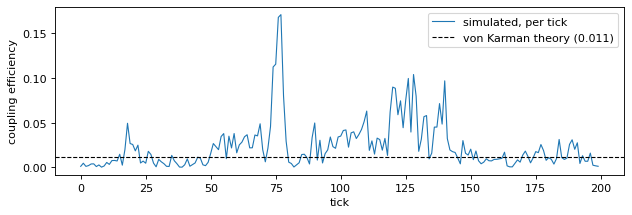

aperture 1.02 m, D/r0 = 10.2: mean 0.024, std 0.027 over 200 ticks (theory 0.011)
written: runs/quickstart/analysis/fiber.csv, runs/quickstart/analysis/fiber_summary.json


In [7]:
fiber = opal.analyze_run("runs/quickstart", "fiber", frames="all")
theory, stats = fiber["theory"]["eta"], fiber["statistics"]

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(fiber["steps"], fiber["values"], lw=1, label="simulated, per tick")
ax.axhline(theory, color="k", ls="--", lw=1, label=f"von Karman theory ({theory:.3f})")
ax.set(xlabel="tick", ylabel="coupling efficiency")
ax.legend()
plt.tight_layout()
plt.show()
print(f"aperture {fiber['aperture_m']:.2f} m, D/r0 = {fiber['D_over_r0']:.1f}: "
      f"mean {stats['mean']:.3f}, std {stats['std']:.3f} over {stats['count']} ticks (theory {theory:.3f})")
print("written:", ", ".join(Path(p).as_posix() for p in fiber["files"].values()))

## Next steps

| Notebook | What it shows |
|---|---|
| `02_run_modes` | device / host / chunked / no_save, the memory guard, bit-identical outputs |
| `03_checkpoint_resume` | long runs in pieces, bit-exact |
| `04_leo_pass` | a full LEO pass with exact per-segment r₀ switching |
| `05_ml_dataset` | labelled datasets for machine learning |
| `06_fiber_coupling` | Monte-Carlo coupling efficiency vs theory |
| `07_cli_tour` | every `opal` command |
| `08_turbulence_schedules` | turbulence that changes while the run is going |